# **1- Enviroment Setup and Libraries installation**

Install Required libraries

In [ ]:
!pip install numpy pandas matplotlib seaborn
!pip install torch torchvision
!pip install scikit-learn scikit-image
!pip install joblib

1.2 - Import Required Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
import sklearn
import skimage

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

NumPy: 2.4.6
Pandas: 2.2.3
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
GPU available: False


# **2 - Create a sample RGB image**

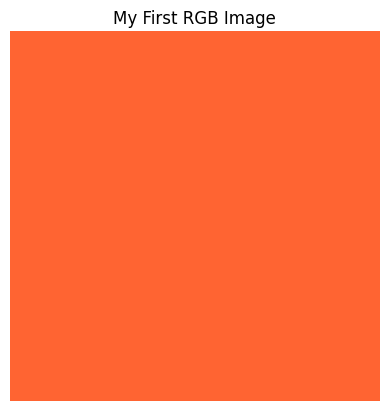

Image shape: (32, 32, 3)
Pixel value: [255 100  50]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Create a sample RGB image
image = np.zeros((32, 32, 3), dtype=np.uint8)

# Assign colours
image[:, :, 0] = 255  # Red channel
image[:, :, 1] = 100  # Green channel
image[:, :, 2] = 50   # Blue channel

# Display image
plt.imshow(image)
plt.title("My First RGB Image")
plt.axis("off")
plt.show()

print("Image shape:", image.shape)
print("Pixel value:", image[0, 0])

# **3 : CIFAR-10 Dataset Loading**

In [ ]:
import torchvision
import torchvision.transforms as transforms

transform = transforms.ToTensor()

train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 50000
Testing images: 10000


 3.2 Define Classes Names

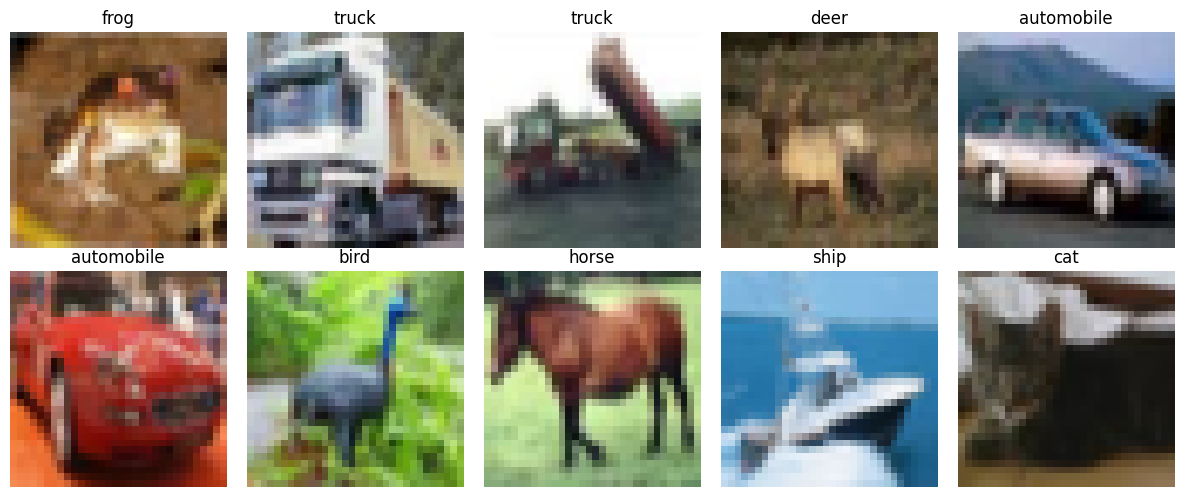

In [ ]:
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    ax.imshow(image.permute(1, 2, 0))
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

# **4.1: Import libraries for HOG**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.feature import hog
from skimage.color import rgb2gray

print("Libraries imported successfully!")

Libraries imported successfully!


4.2: Define the HOG extraction function

In [ ]:
def extract_hog_features(image):

    gray_image = rgb2gray(image)

    features = hog(
        gray_image,
        orientations=9,
        pixels_per_cell=(4, 4),
        cells_per_block=(2, 2),
        visualize=False
    )

    return features.astype(np.float32)

4.3: Define the colour histogram function

In [ ]:
def extract_color_histogram(image, bins=16):

    features = []

    for channel in range(3):

        hist, _ = np.histogram(
            image[:, :, channel],
            bins=bins,
            range=(0, 1),
            density=True
        )

        features.extend(hist)

    return np.array(features, dtype=np.float32)

4.4: Extract features from all 50,000 training images

In [ ]:
from tqdm.notebook import tqdm

In [ ]:
|hog_features_all = []
color_features_all = []
true_labels = []

for i in tqdm (range(len(train_dataset))):

    image, label = train_dataset[i]

    # Convert image from PyTorch tensor to NumPy
    image = image.permute(1, 2, 0).numpy()

    # Extract HOG features
    hog_feature = extract_hog_features(image)

    # Extract colour histogram
    color_feature = extract_color_histogram(image)

    hog_features_all.append(hog_feature)
    color_features_all.append(color_feature)

    true_labels.append(label)


X_hog = np.array(hog_features_all, dtype=np.float32)
X_color = np.array(color_features_all, dtype=np.float32)
y_train = np.array(true_labels, dtype=np.int64)

print("HOG shape:", X_hog.shape)
print("Colour shape:", X_color.shape)
print("Labels shape:", y_train.shape)

SyntaxError: invalid syntax (989999802.py, line 1)

4.5: Save your extracted features

In [ ]:
np.save("X_hog.npy", X_hog)
np.save("X_color.npy", X_color)
np.save("y_train.npy", y_train)

print("All feature files saved successfully!")

In [ ]:
 from google.colab import files

files.download("X_hog.npy")
files.download("X_color.npy")
files.download("y_train.npy")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

4.6: Verify the saved features

In [ ]:
print("Number of training samples:", len(y_train))
print("HOG feature dimensions:", X_hog.shape[1])
print("Colour feature dimensions:", X_color.shape[1])

print("HOG contains NaN:", np.isnan(X_hog).any())
print("Colour contains NaN:", np.isnan(X_color).any())

Number of training samples: 50000
HOG feature dimensions: 1764
Colour feature dimensions: 48
HOG contains NaN: False
Colour contains NaN: False


# **5: Generate biased complementary labels**

**5.1: Understand complementary labels**
In ordinary supervised learning, an image has its correct class.
In complementary-label learning, the annotation tells us a class that the image does NOT belong to.

**5.2: Create the transition matrix**

The transition matrix describes the probability of receiving a particular complementary label given the actual class.

Mathematically: Ty,c​=P(Yˉ=c∣Y=y)

Where:

y = actual class.

c = complementary class.

T = transition matrix.

For CIFAR-10, it will be a 10 × 10 matrix.

In [ ]:
def make_transition_matrix(bias_strength=0.75):

    num_classes = 10

    T = np.zeros((num_classes, num_classes))

    for y in range(num_classes):

        preferred_class = (y + 1) % num_classes

        T[y, :] = (1 - bias_strength) / (num_classes - 2)

        # A complementary label can never be the true class
        T[y, y] = 0

        # Give one incorrect class a higher probability
        T[y, preferred_class] = bias_strength

    return T

5.3: Generate the transition matrix

In [ ]:
T = make_transition_matrix(bias_strength=0.75)

print("Transition Matrix:")
print(np.round(T, 3))

print("\nRow sums:")
print(T.sum(axis=1))

Transition Matrix:
[[0.    0.75  0.031 0.031 0.031 0.031 0.031 0.031 0.031 0.031]
 [0.031 0.    0.75  0.031 0.031 0.031 0.031 0.031 0.031 0.031]
 [0.031 0.031 0.    0.75  0.031 0.031 0.031 0.031 0.031 0.031]
 [0.031 0.031 0.031 0.    0.75  0.031 0.031 0.031 0.031 0.031]
 [0.031 0.031 0.031 0.031 0.    0.75  0.031 0.031 0.031 0.031]
 [0.031 0.031 0.031 0.031 0.031 0.    0.75  0.031 0.031 0.031]
 [0.031 0.031 0.031 0.031 0.031 0.031 0.    0.75  0.031 0.031]
 [0.031 0.031 0.031 0.031 0.031 0.031 0.031 0.    0.75  0.031]
 [0.031 0.031 0.031 0.031 0.031 0.031 0.031 0.031 0.    0.75 ]
 [0.75  0.031 0.031 0.031 0.031 0.031 0.031 0.031 0.031 0.   ]]

Row sums:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


5.4: Generate complementary labels

In [ ]:
def generate_complementary_labels(y, T, seed=42):

    rng = np.random.default_rng(seed)

    complementary_labels = []

    for true_class in y:

        probabilities = T[true_class]

        complementary_class = rng.choice(
            len(probabilities),
            p=probabilities
        )

        complementary_labels.append(complementary_class)

    return np.array(complementary_labels, dtype=np.int64)

In [ ]:
y_complementary = generate_complementary_labels(
    y_train,
    T,
    seed=42
)

print("Actual labels shape:", y_train.shape)
print("Complementary labels shape:", y_complementary.shape)

print("First 20 actual labels:")
print(y_train[:20])

print("\nFirst 20 complementary labels:")
print(y_complementary[:20])

Actual labels shape: (50000,)
Complementary labels shape: (50000,)
First 20 actual labels:
[6 9 9 4 1 1 2 7 8 3 4 7 7 2 9 9 9 3 2 6]

First 20 complementary labels:
[7 0 4 5 2 9 3 8 4 4 5 8 8 4 0 0 0 2 4 7]


5.5: Verify that complementary labels are valid

In [ ]:
same_labels = np.sum(y_train == y_complementary)

print("Number of invalid complementary labels:", same_labels)

Number of invalid complementary labels: 0


5.6: Visualise the transition matrix

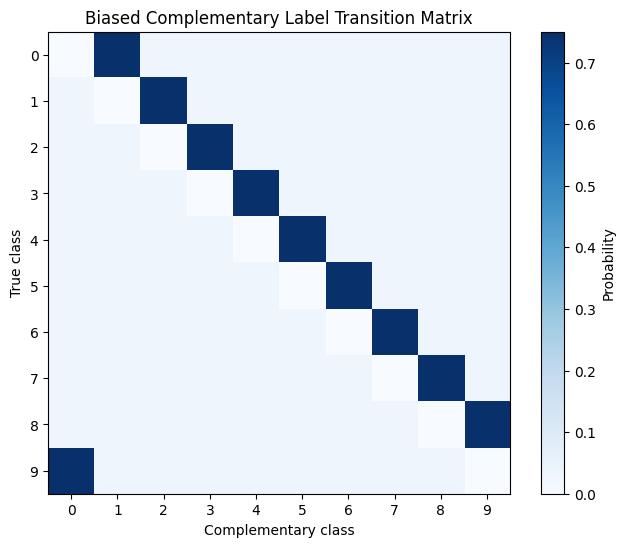

In [ ]:
plt.figure(figsize=(8, 6))

plt.imshow(T, cmap="Blues")

plt.colorbar(label="Probability")

plt.xlabel("Complementary class")
plt.ylabel("True class")

plt.title("Biased Complementary Label Transition Matrix")

plt.xticks(range(10))
plt.yticks(range(10))

plt.show()

5.7: Save the complementary labels

In [ ]:

np.save("y_complementary.npy", y_complementary)
np.save("transition_matrix.npy", T)

print("Complementary labels and transition matrix saved!")

Complementary labels and transition matrix saved!


# **6: Implement complementary-label loss functions**

6.2: Import PyTorch

In [ ]:
import torch
import torch.nn.functional as F

print("PyTorch imported successfully!")

PyTorch imported successfully!


6.3: Convert the transition matrix into a PyTorch tensor

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

T_tensor = torch.tensor(
    T,
    dtype=torch.float32,
    device=device
)

print("Device:", device)
print("Transition matrix shape:", T_tensor.shape)

Device: cpu
Transition matrix shape: torch.Size([10, 10])


6.4: Implement naive complementary-label loss

In [ ]:
def naive_complementary_loss(logits, complementary_labels):

    probabilities = F.softmax(logits, dim=1)

    selected_probabilities = probabilities.gather(
        1,
        complementary_labels.view(-1, 1)
    )

    loss = -torch.log(
        (1 - selected_probabilities).clamp(min=1e-7)
    )

    return loss.mean()

6.5: Implement bias-aware complementary-label loss

In [ ]:
def bias_aware_complementary_loss(
    logits,
    complementary_labels,
    transition_matrix
):

    probabilities = F.softmax(logits, dim=1)

    # Probability of each possible complementary label
    complementary_probabilities = probabilities @ transition_matrix

    selected_probabilities = complementary_probabilities.gather(
        1,
        complementary_labels.view(-1, 1)
    )

    loss = -torch.log(
        selected_probabilities.clamp(min=1e-7)
    )

    return loss.mean()

6.6: Implement supervised reference loss

In [ ]:
def supervised_loss(logits, true_labels):

    return F.cross_entropy(logits, true_labels)

6.7: Test all three loss functions

In [ ]:
# Create artificial predictions for 8 images
batch_size = 8
num_classes = 10

logits = torch.randn(
    batch_size,
    num_classes,
    requires_grad=True,
    device=device
)

# Artificial complementary labels
complementary_labels = torch.tensor(
    [1, 2, 3, 4, 5, 6, 7, 8],
    dtype=torch.long,
    device=device
)

# Artificial true labels for supervised reference only
true_labels = torch.tensor(
    [0, 1, 2, 3, 4, 5, 6, 7],
    dtype=torch.long,
    device=device
)

loss_naive = naive_complementary_loss(
    logits,
    complementary_labels
)

loss_bias = bias_aware_complementary_loss(
    logits,
    complementary_labels,
    T_tensor
)

loss_supervised = supervised_loss(
    logits,
    true_labels
)

print("Naive complementary loss:", loss_naive.item())
print("Bias-aware complementary loss:", loss_bias.item())
print("Supervised reference loss:", loss_supervised.item())

Naive complementary loss: 0.0979103371500969
Bias-aware complementary loss: 2.477787494659424
Supervised reference loss: 2.684622049331665


6.8: Test gradient calculation

In [ ]:
loss_bias.backward()

print("Gradient calculation successful!")
print("Gradient shape:", logits.grad.shape)

Gradient calculation successful!
Gradient shape: torch.Size([8, 10])


6.9: Save the mathematical components

In [ ]:
import numpy as np

np.save("transition_matrix.npy", T)
np.save("complementary_labels.npy", y_complementary)

print("Stage 6 mathematical components are ready!")

Stage 6 mathematical components are ready!


# **7: Build the CNN feature extractor**

7.2 Import PyTorch libraries

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

print("PyTorch ready!")
print("Available device:", "GPU" if torch.cuda.is_available() else "CPU")

PyTorch ready!
Available device: CPU


7.3 Define our CNN architecture

In [ ]:
class CNNEncoder(nn.Module):

    def __init__(self):

        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)

        self.pool = nn.MaxPool2d(2)

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

    def forward(self, x):

        x = self.pool(F.relu(self.bn1(self.conv1(x))))

        x = self.pool(F.relu(self.bn2(self.conv2(x))))

        x = F.relu(self.bn3(self.conv3(x)))

        x = self.global_pool(x)

        x = torch.flatten(x, 1)

        return x

7.4 Test the CNN

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

cnn = CNNEncoder().to(device)

sample_image, sample_label = train_dataset[0]

sample_image = sample_image.unsqueeze(0).to(device)

with torch.no_grad():
    cnn_features = cnn(sample_image)

print("Input image shape:", sample_image.shape)
print("CNN feature shape:", cnn_features.shape)

Input image shape: torch.Size([1, 3, 32, 32])
CNN feature shape: torch.Size([1, 128])


# **8: Combine the three image views**

8.2 Prepare our feature data

In [ ]:
X_hog_tensor = torch.tensor(
    X_hog,
    dtype=torch.float32
)

X_color_tensor = torch.tensor(
    X_color,
    dtype=torch.float32
)

print("HOG tensor:", X_hog_tensor.shape)
print("Colour tensor:", X_color_tensor.shape)

HOG tensor: torch.Size([50000, 1764])
Colour tensor: torch.Size([50000, 48])


8.3 Create the multi-view architecture

In [ ]:
class MultiViewModel(nn.Module):

    def __init__(self, mode="multiview", num_classes=10):

        super().__init__()

        self.mode = mode

        self.cnn = CNNEncoder()

        self.hog_branch = nn.Sequential(
            nn.Linear(1764, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.ReLU()
        )

        self.color_branch = nn.Sequential(
            nn.Linear(48, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU()
        )

        if mode == "multiview":
            input_size = 288

        elif mode == "cnn":
            input_size = 128

        elif mode == "hog":
            input_size = 128

        elif mode == "color":
            input_size = 32

        else:
            raise ValueError("Invalid model mode")

        self.classifier = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, image, hog_features, color_features):

        if self.mode == "multiview":

            cnn_features = self.cnn(image)

            hog_output = self.hog_branch(hog_features)

            color_output = self.color_branch(color_features)

            combined = torch.cat(
                [cnn_features, hog_output, color_output],
                dim=1
            )

        elif self.mode == "cnn":

            combined = self.cnn(image)

        elif self.mode == "hog":

            combined = self.hog_branch(hog_features)

        elif self.mode == "color":

            combined = self.color_branch(color_features)

        return self.classifier(combined)

8.4 Test the combined model

In [ ]:
test_model = MultiViewModel(mode="multiview").to(device)

sample_image, _ = train_dataset[0]

sample_image = sample_image.unsqueeze(0).to(device)

sample_hog = X_hog_tensor[0].unsqueeze(0).to(device)

sample_color = X_color_tensor[0].unsqueeze(0).to(device)

with torch.no_grad():

    output = test_model(
        sample_image,
        sample_hog,
        sample_color
    )

print("Model output shape:", output.shape)

Model output shape: torch.Size([1, 10])


 # **9: Train the machine learning models**

9.1 Prepare the training and validation datasets

In [ ]:
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import copy
import random

In [ ]:
indices = np.arange(len(y_train))

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(train_indices))
print("Validation samples:", len(val_indices))

Training samples: 45000
Validation samples: 5000


9.2 Standardise the HOG and colour features

In [ ]:
hog_scaler = StandardScaler()
color_scaler = StandardScaler()

X_hog_scaled = np.zeros_like(X_hog, dtype=np.float32)
X_color_scaled = np.zeros_like(X_color, dtype=np.float32)

X_hog_scaled[train_indices] = hog_scaler.fit_transform(
    X_hog[train_indices]
).astype(np.float32)

X_hog_scaled[val_indices] = hog_scaler.transform(
    X_hog[val_indices]
).astype(np.float32)

X_color_scaled[train_indices] = color_scaler.fit_transform(
    X_color[train_indices]
).astype(np.float32)

X_color_scaled[val_indices] = color_scaler.transform(
    X_color[val_indices]
).astype(np.float32)

print("Feature standardisation completed.")

Feature standardisation completed.


9.3 Create a PyTorch dataset

In [ ]:
class CIFARMultiViewDataset(Dataset):

    def __init__(
        self,
        indices,
        base_dataset,
        hog_features,
        color_features,
        complementary_labels,
        true_labels
    ):

        self.indices = indices
        self.base_dataset = base_dataset
        self.hog_features = hog_features
        self.color_features = color_features
        self.complementary_labels = complementary_labels
        self.true_labels = true_labels

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):

        idx = self.indices[position]

        image, _ = self.base_dataset[idx]

        hog_feature = torch.from_numpy(
            self.hog_features[idx]
        )

        color_feature = torch.from_numpy(
            self.color_features[idx]
        )

        complementary_label = int(
            self.complementary_labels[idx]
        )

        true_label = int(self.true_labels[idx])

        return (
            image,
            hog_feature,
            color_feature,
            complementary_label,
            true_label
        )

In [ ]:
train_data = CIFARMultiViewDataset(
    train_indices,
    train_dataset,
    X_hog_scaled,
    X_color_scaled,
    y_complementary,
    y_train
)

val_data = CIFARMultiViewDataset(
    val_indices,
    train_dataset,
    X_hog_scaled,
    X_color_scaled,
    y_complementary,
    y_train
)

9.4 Create data loaders

In [ ]:
BATCH_SIZE = 128

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 352
Validation batches: 40


9.5 Prepare the loss functions

In [ ]:
def naive_complementary_loss(logits, complementary_labels):

    probabilities = F.softmax(logits, dim=1)

    selected = probabilities.gather(
        1,
        complementary_labels.view(-1, 1)
    )

    return -torch.log(
        (1 - selected).clamp(min=1e-7)
    ).mean()


def bias_aware_complementary_loss(
    logits,
    complementary_labels,
    transition_matrix
):

    probabilities = F.softmax(logits, dim=1)

    complementary_probabilities = probabilities @ transition_matrix

    selected = complementary_probabilities.gather(
        1,
        complementary_labels.view(-1, 1)
    )

    return -torch.log(
        selected.clamp(min=1e-7)
    ).mean()

In [ ]:
T_tensor = torch.tensor(
    T,
    dtype=torch.float32,
    device=device
)

print("Transition matrix ready:", T_tensor.shape)

Transition matrix ready: torch.Size([10, 10])


9.6 Create a validation function

In [ ]:
def evaluate_validation(model, loader):

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, hogs, colors, complements, true_labels in loader:

            images = images.to(device)
            hogs = hogs.to(device)
            colors = colors.to(device)
            true_labels = true_labels.to(device)

            logits = model(images, hogs, colors)

            predictions = logits.argmax(dim=1)

            correct += (predictions == true_labels).sum().item()
            total += true_labels.size(0)

    return 100 * correct / total

9.7 Create the training function

In [ ]:
def train_one_experiment(
    objective,
    mode="multiview",
    epochs=5
):

    model = MultiViewModel(mode=mode).to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    best_accuracy = -1
    best_state = copy.deepcopy(model.state_dict())

    history = []

    for epoch in range(epochs):

        model.train()

        total_loss = 0

        for images, hogs, colors, complements, true_labels in train_loader:

            images = images.to(device)
            hogs = hogs.to(device)
            colors = colors.to(device)

            complements = complements.to(device)
            true_labels = true_labels.to(device)

            optimizer.zero_grad()

            logits = model(images, hogs, colors)

            if objective == "supervised":

                loss = F.cross_entropy(logits, true_labels)

            elif objective == "naive":

                loss = naive_complementary_loss(
                    logits,
                    complements
                )

            elif objective == "bias":

                loss = bias_aware_complementary_loss(
                    logits,
                    complements,
                    T_tensor
                )

            else:

                raise ValueError("Unknown objective")

            loss.backward()

            optimizer.step()

            total_loss += loss.item()

        average_loss = total_loss / len(train_loader)

        validation_accuracy = evaluate_validation(
            model,
            val_loader
        )

        history.append({
            "epoch": epoch + 1,
            "loss": average_loss,
            "validation_accuracy": validation_accuracy
        })

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss: {average_loss:.4f} | "
            f"Validation accuracy: {validation_accuracy:.2f}%"
        )

        if validation_accuracy > best_accuracy:

            best_accuracy = validation_accuracy

            best_state = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_state)

    filename = f"model_{objective}_{mode}.pth"

    torch.save(model.state_dict(), filename)

    print("Best validation accuracy:", round(best_accuracy, 2))
    print("Model saved:", filename)

    return model, history

9.8 Train the three main models

In [ ]:
EPOCHS = 5

supervised_model, supervised_history = train_one_experiment(
    objective="supervised",
    mode="multiview",
    epochs=EPOCHS
)

naive_model, naive_history = train_one_experiment(
    objective="naive",
    mode="multiview",
    epochs=EPOCHS
)

bias_model, bias_history = train_one_experiment(
    objective="bias",
    mode="multiview",
    epochs=EPOCHS
)

Epoch 1/5 | Loss: 1.2659 | Validation accuracy: 63.80%
Epoch 2/5 | Loss: 0.9335 | Validation accuracy: 63.76%
Epoch 3/5 | Loss: 0.8012 | Validation accuracy: 65.50%
Epoch 4/5 | Loss: 0.7042 | Validation accuracy: 67.54%
Epoch 5/5 | Loss: 0.6235 | Validation accuracy: 68.14%
Best validation accuracy: 68.14
Model saved: model_supervised_multiview.pth
Epoch 1/5 | Loss: 0.0503 | Validation accuracy: 13.36%
Epoch 2/5 | Loss: 0.0394 | Validation accuracy: 13.96%
Epoch 3/5 | Loss: 0.0328 | Validation accuracy: 20.38%
Epoch 4/5 | Loss: 0.0263 | Validation accuracy: 20.70%
Epoch 5/5 | Loss: 0.0214 | Validation accuracy: 18.54%
Best validation accuracy: 20.7
Model saved: model_naive_multiview.pth
Epoch 1/5 | Loss: 1.8006 | Validation accuracy: 58.82%
Epoch 2/5 | Loss: 1.6100 | Validation accuracy: 56.68%
Epoch 3/5 | Loss: 1.5264 | Validation accuracy: 55.94%
Epoch 4/5 | Loss: 1.4574 | Validation accuracy: 65.54%
Epoch 5/5 | Loss: 1.4049 | Validation accuracy: 62.70%
Best validation accuracy: 65.

9.9 Conduct view-ablation experiments

In [ ]:
cnn_only_model, cnn_only_history = train_one_experiment(
    objective="bias",
    mode="cnn",
    epochs=EPOCHS
)

hog_only_model, hog_only_history = train_one_experiment(
    objective="bias",
    mode="hog",
    epochs=EPOCHS
)

color_only_model, color_only_history = train_one_experiment(
    objective="bias",
    mode="color",
    epochs=EPOCHS
)

Epoch 1/5 | Loss: 1.9443 | Validation accuracy: 39.58%
Epoch 2/5 | Loss: 1.7740 | Validation accuracy: 54.40%
Epoch 3/5 | Loss: 1.7071 | Validation accuracy: 51.54%
Epoch 4/5 | Loss: 1.6616 | Validation accuracy: 47.88%
Epoch 5/5 | Loss: 1.6240 | Validation accuracy: 57.46%
Best validation accuracy: 57.46
Model saved: model_bias_cnn.pth
Epoch 1/5 | Loss: 1.8985 | Validation accuracy: 53.52%
Epoch 2/5 | Loss: 1.7287 | Validation accuracy: 55.78%
Epoch 3/5 | Loss: 1.6454 | Validation accuracy: 56.16%
Epoch 4/5 | Loss: 1.5816 | Validation accuracy: 57.20%
Epoch 5/5 | Loss: 1.5222 | Validation accuracy: 56.42%
Best validation accuracy: 57.2
Model saved: model_bias_hog.pth
Epoch 1/5 | Loss: 2.1695 | Validation accuracy: 28.78%
Epoch 2/5 | Loss: 2.0918 | Validation accuracy: 32.04%
Epoch 3/5 | Loss: 2.0659 | Validation accuracy: 33.34%
Epoch 4/5 | Loss: 2.0526 | Validation accuracy: 34.10%
Epoch 5/5 | Loss: 2.0440 | Validation accuracy: 34.50%
Best validation accuracy: 34.5
Model saved: mode

# **10: Evaluate the models and compare results**

10.1 Extract HOG and colour features from the test dataset

In [ ]:
from tqdm.notebook import tqdm

test_hog_features = []
test_color_features = []
test_labels = []

for i in tqdm(range(len(test_dataset))):

    image, label = test_dataset[i]

    image_array = image.permute(1, 2, 0).numpy()

    test_hog_features.append(
        extract_hog_features(image_array)
    )

    test_color_features.append(
        extract_color_histogram(image_array)
    )

    test_labels.append(label)


X_hog_test = np.array(
    test_hog_features,
    dtype=np.float32
)

X_color_test = np.array(
    test_color_features,
    dtype=np.float32
)

y_test = np.array(
    test_labels,
    dtype=np.int64
)

print("Test HOG:", X_hog_test.shape)
print("Test colour:", X_color_test.shape)
print("Test labels:", y_test.shape)

  0%|          | 0/10000 [00:00<?, ?it/s]

Test HOG: (10000, 1764)
Test colour: (10000, 48)
Test labels: (10000,)


10.2 Standardise the test features

In [ ]:
X_hog_test_scaled = hog_scaler.transform(
    X_hog_test
).astype(np.float32)

X_color_test_scaled = color_scaler.transform(
    X_color_test
).astype(np.float32)

print("Test feature standardisation completed.")

Test feature standardisation completed.


10.3 Create the test dataset

In [ ]:
test_indices = np.arange(len(test_dataset))

test_data = CIFARMultiViewDataset(
    test_indices,
    test_dataset,
    X_hog_test_scaled,
    X_color_test_scaled,
    np.zeros(len(y_test), dtype=np.int64),
    y_test
)

test_loader = DataLoader(
    test_data,
    batch_size=128,
    shuffle=False,
    num_workers=0
)

print("Test dataset ready.")

Test dataset ready.


10.4 Create the evaluation function

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

def evaluate_test_model(model, loader):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, hogs, colors, complements, true_labels in loader:

            images = images.to(device)
            hogs = hogs.to(device)
            colors = colors.to(device)

            logits = model(images, hogs, colors)

            predictions = logits.argmax(dim=1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                true_labels.numpy()
            )

    accuracy = accuracy_score(
        all_labels,
        all_predictions
    )

    precision = precision_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )

    return {
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": f1,
        "Predictions": np.array(all_predictions),
        "True Labels": np.array(all_labels)
    }

10.5 Evaluate all six models

In [ ]:
models = {
    "Supervised Multi-view": supervised_model,
    "Naive Multi-view": naive_model,
    "Bias-aware Multi-view": bias_model,
    "Bias-aware CNN-only": cnn_only_model,
    "Bias-aware HOG-only": hog_only_model,
    "Bias-aware Colour-only": color_only_model
}

results = {}

for name, model in models.items():

    print("\nEvaluating:", name)

    results[name] = evaluate_test_model(
        model,
        test_loader
    )

    print("Accuracy:", round(results[name]["Accuracy"] * 100, 2), "%")
    print("Macro F1:", round(results[name]["Macro F1"], 4))


Evaluating: Supervised Multi-view
Accuracy: 68.1 %
Macro F1: 0.6706

Evaluating: Naive Multi-view
Accuracy: 20.95 %
Macro F1: 0.1445

Evaluating: Bias-aware Multi-view
Accuracy: 65.45 %
Macro F1: 0.6563

Evaluating: Bias-aware CNN-only
Accuracy: 55.88 %
Macro F1: 0.5561

Evaluating: Bias-aware HOG-only
Accuracy: 57.05 %
Macro F1: 0.5675

Evaluating: Bias-aware Colour-only
Accuracy: 34.07 %
Macro F1: 0.3337


10.6 Create a performance comparison table

In [ ]:
import pandas as pd

comparison = []

for name, result in results.items():

    comparison.append({
        "Model": name,
        "Accuracy (%)": result["Accuracy"] * 100,
        "Precision": result["Macro Precision"],
        "Recall": result["Macro Recall"],
        "Macro F1": result["Macro F1"]
    })

results_df = pd.DataFrame(comparison)

print(results_df.round(4))

                    Model  Accuracy (%)  Precision  Recall  Macro F1
0   Supervised Multi-view         68.10     0.6923  0.6810    0.6706
1        Naive Multi-view         20.95     0.1744  0.2095    0.1445
2   Bias-aware Multi-view         65.45     0.6648  0.6545    0.6563
3     Bias-aware CNN-only         55.88     0.6459  0.5588    0.5561
4     Bias-aware HOG-only         57.05     0.5707  0.5705    0.5675
5  Bias-aware Colour-only         34.07     0.3334  0.3407    0.3337


10.7 Visualise the accuracy comparison

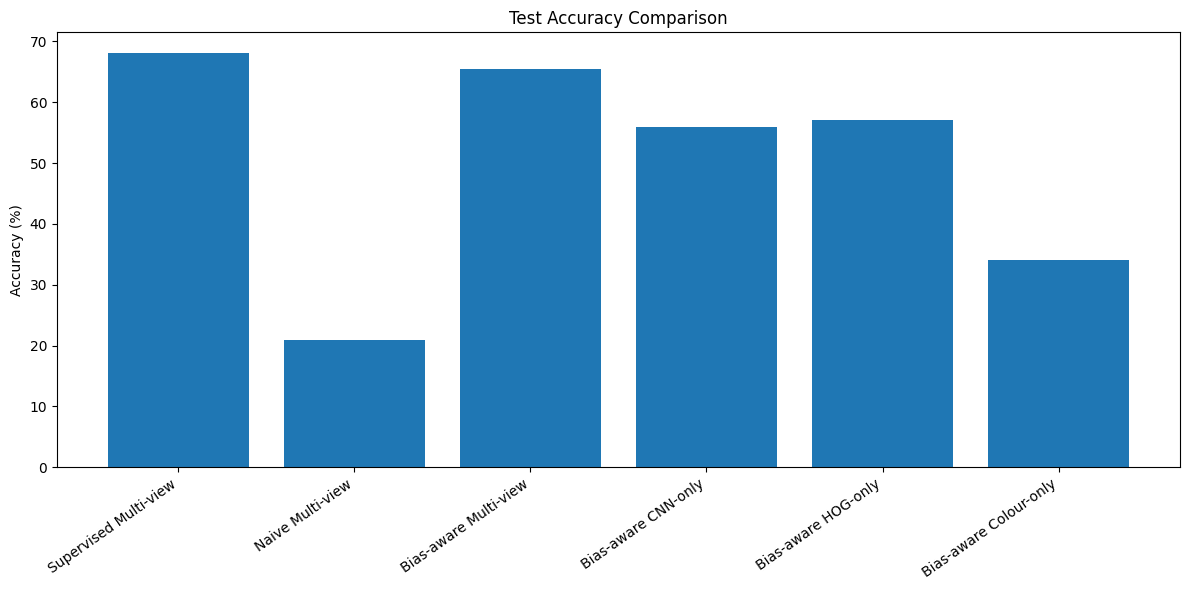

In [ ]:
plt.figure(figsize=(12, 6))

plt.bar(
    results_df["Model"],
    results_df["Accuracy (%)"]
)

plt.title("Test Accuracy Comparison")

plt.ylabel("Accuracy (%)")

plt.xticks(
    rotation=35,
    ha="right"
)

plt.tight_layout()
plt.show()

10.8 Create a confusion matrix

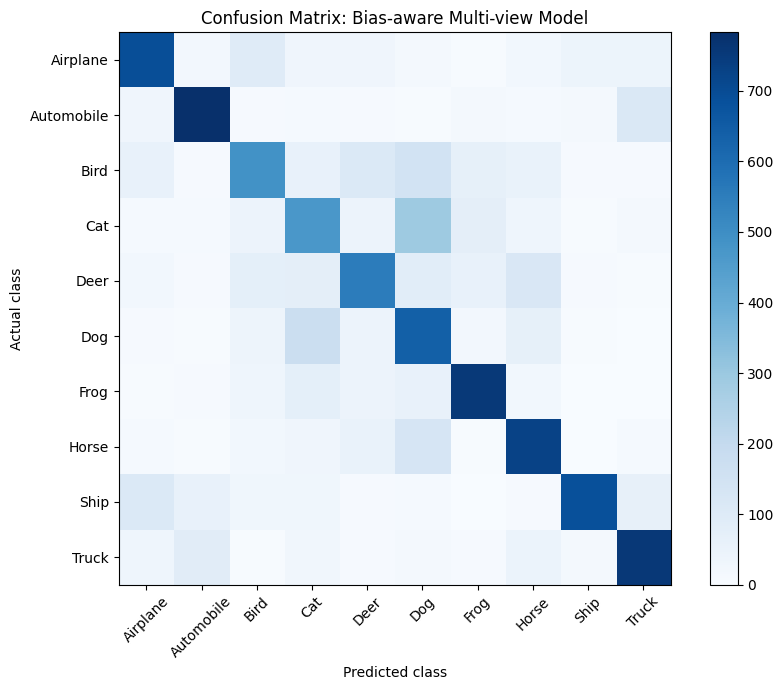

In [ ]:
bias_predictions = results["Bias-aware Multi-view"]["Predictions"]

cm = confusion_matrix(
    y_test,
    bias_predictions
)

plt.figure(figsize=(9, 7))

plt.imshow(cm, cmap="Blues")

plt.colorbar()

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

plt.xticks(range(10), class_names, rotation=45)
plt.yticks(range(10), class_names)

plt.xlabel("Predicted class")
plt.ylabel("Actual class")

plt.title("Confusion Matrix: Bias-aware Multi-view Model")

plt.tight_layout()
plt.show()

10.9 Generate a classification report

In [ ]:
print(
    classification_report(
        results["Bias-aware Multi-view"]["True Labels"],
        results["Bias-aware Multi-view"]["Predictions"],
        target_names=class_names
    )
)

              precision    recall  f1-score   support

    Airplane       0.70      0.69      0.70      1000
  Automobile       0.79      0.78      0.79      1000
        Bird       0.58      0.49      0.53      1000
         Cat       0.48      0.47      0.47      1000
        Deer       0.61      0.55      0.58      1000
         Dog       0.46      0.64      0.53      1000
        Frog       0.75      0.75      0.75      1000
       Horse       0.66      0.73      0.69      1000
        Ship       0.87      0.69      0.77      1000
       Truck       0.74      0.76      0.75      1000

    accuracy                           0.65     10000
   macro avg       0.66      0.65      0.66     10000
weighted avg       0.66      0.65      0.66     10000



10.10 Save our experimental results

In [ ]:
results_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

np.save(
    "bias_aware_predictions.npy",
    results["Bias-aware Multi-view"]["Predictions"]
)

print("Experimental results saved successfully!")

Experimental results saved successfully!


Download

In [ ]:
from google.colab import files

files.download("model_comparison_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **11: Robustness and reproducibility experiments**

In [ ]:

import inspect

print("Training function:")
print(inspect.signature(train_one_experiment))

print("\nModel constructor:")
print(inspect.signature(MultiViewModel))

print("\nTest evaluation function:")
print(inspect.signature(evaluate_test_model))

print("\nExisting training and evaluation variables:")
for name in [
    "train_loader",
    "val_loader",
    "test_loader",
    "bias_model",
    "results_df",
    "models"
]:
    print(name, ":", "Available" if name in globals() else "Not found")


Training function:
(objective, mode='multiview', epochs=5)

Model constructor:
(mode='multiview', num_classes=10)

Test evaluation function:
(model, loader)

Existing training and evaluation variables:
train_loader : Available
val_loader : Available
test_loader : Available
bias_model : Available
results_df : Available
models : Available


# **12: Multi-view ablation and comparative analysis**

In [ ]:

print("Existing model comparison:")

display(results_df)

print("\nAvailable result columns:")
print(results_df.columns.tolist())


Existing model comparison:


,Model,Accuracy (%),Precision,Recall,Macro F1
0,Supervised Multi-view,68.10,0.692313,0.6810,0.670560
1,Naive Multi-view,20.95,0.174357,0.2095,0.144485
2,Bias-aware Multi-view,65.45,0.664800,0.6545,0.656284
3,Bias-aware CNN-only,55.88,0.645891,0.5588,0.556100
4,Bias-aware HOG-only,57.05,0.570685,0.5705,0.567531
5,Bias-aware Colour-only,34.07,0.333433,0.3407,0.333704



Available result columns:
['Model', 'Accuracy (%)', 'Precision', 'Recall', 'Macro F1']


# **13: Research interpretation and limitations**

## **TITLE**

# **Bias-Aware Multi-View Complementary Label Learning for Image Classification**

1. Abstract

2. Introduction
   2.1 Background
   2.2 Research Problem
   2.3 Research Objectives
   2.4 Research Contributions

3. Literature Review
   3.1 Complementary Label Learning
   3.2 Biased Complementary Labels
   3.3 Multi-View Learning
   3.4 CNN-Based Image Classification

4. Proposed Methodology
   4.1 CIFAR-10 Dataset
   4.2 HOG Feature Extraction
   4.3 RGB Colour Histograms
   4.4 CNN Feature Extraction
   4.5 Complementary Label Generation
   4.6 Bias-Aware Learning Objective
   4.7 Multi-View Feature Fusion

5. Experimental Setup

6. Results and Comparative Analysis
   6.1 Model Comparison
   6.2 Ablation Study
   6.3 Robustness Experiments

7. Discussion

8. Limitations

9. Conclusion and Future Work

10. References
